# Telecom Customer Churn - Exploratory Data Analysis (EDA)

This notebook performs exploratory data analysis on the Telco Customer Churn dataset.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid')


## 1. Load Dataset

In [2]:
df = pd.read_csv('telecom_churn.csv')
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Dataset Shape and Information

In [3]:
print('Dataset Shape:', df.shape)
df.info()


Dataset Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

## 3. Data Cleaning & Handling Missing Values
Convert TotalCharges to numeric and impute missing values with the median.


In [4]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])

# Impute missing values with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())


Missing values:
TotalCharges    11
dtype: int64


## 4. Target Variable Analysis (Churn)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


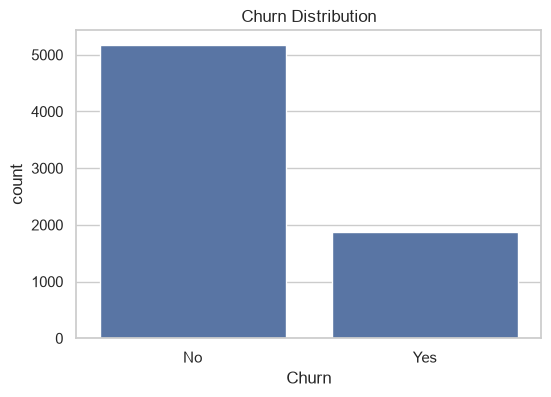

In [5]:
# Churn distribution
print(df['Churn'].value_counts())
print('\nPercentage (%):')
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

# Countplot of Churn
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.show()


## 5. Numerical Features Analysis
Analyze 	enure, MonthlyCharges, and TotalCharges.


In [6]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[num_cols].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2281.92
std,24.56,30.09,2265.27
min,0.00,18.25,18.80
25%,9.00,35.50,402.22
50%,29.00,70.35,1397.48
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [7]:
# Average values by churn status
df.groupby('Churn')[num_cols].mean().round(2)


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2552.88
Yes,17.98,74.44,1531.80


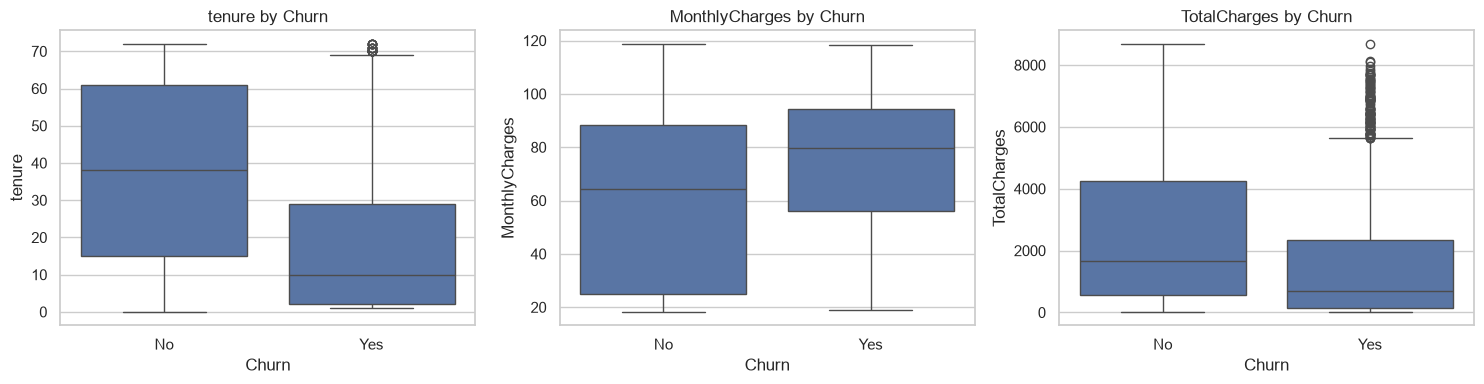

In [8]:
# Boxplots of numerical features by Churn
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Churn', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()


## 6. Categorical Features Analysis
Analyze churn rates across contract types, internet services, and payment methods.


In [9]:
# Churn rate by Contract (%)
(pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100).round(2)


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [10]:
# Churn rate by Internet Service (%)
(pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100).round(2)


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [11]:
# Churn rate by Payment Method (%)
(pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100).round(2)


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


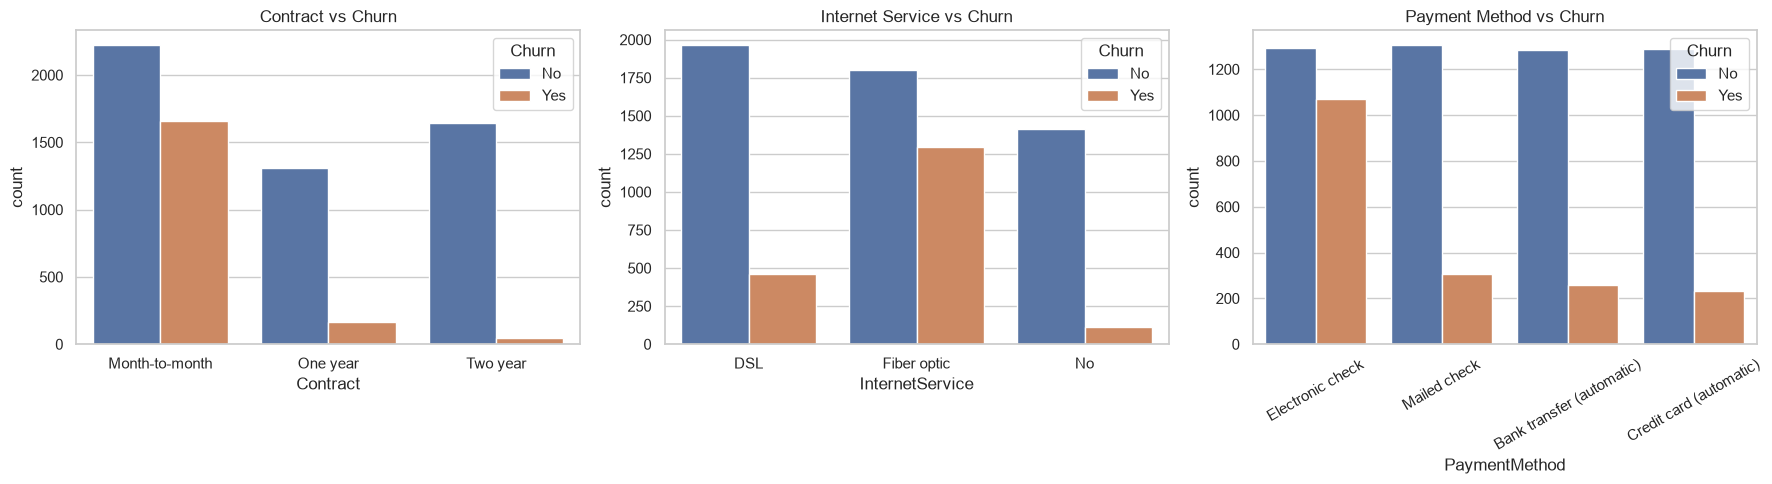

In [12]:
# Visualizing Categorical Features vs Churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0])
axes[0].set_title('Contract vs Churn')

sns.countplot(data=df, x='InternetService', hue='Churn', ax=axes[1])
axes[1].set_title('Internet Service vs Churn')

sns.countplot(data=df, x='PaymentMethod', hue='Churn', ax=axes[2])
axes[2].set_title('Payment Method vs Churn')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 7. Key Findings
- **Contract:** Customers with month-to-month contracts have the highest churn rate (~42.7%).
- **Internet Service:** Fiber optic users have significantly higher churn (~41.9%) than DSL users (~18.9%).
- **Tenure:** Customers who churn have significantly lower average tenure (~18 months vs ~38 months).
- **Payment Method:** Customers using Electronic check churn at the highest rate (~45.3%).
